This is a script to generate Figure 4 of "Wasting is essential: cachexia is driven by a wound-healing adaptation" by Haynes C.; Whelan, C.; and Brown, J.

In [30]:
import numpy as np
import matplotlib.pyplot as plt

from reaction_flask import ReactionFlask

In [31]:
inflammationGenerationParam = 8

[ 2.00e-05  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00  0.00e+00
  0.00e+00  0.00e+00  0.00e+00 -1.00e-06  1.68e-02  0.00e+00  1.00e-06]


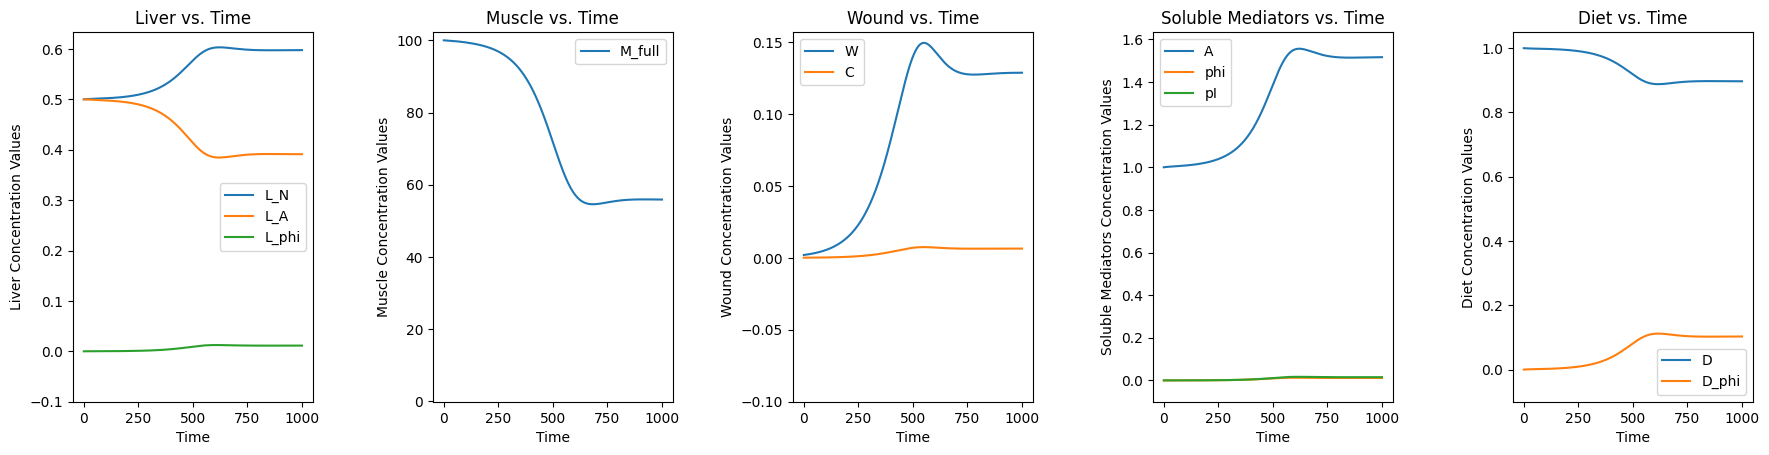

55.89697400175013


In [32]:
cancerGrowthRate = 0.01
cancerN = 20
initialCancerPop = 0.0001

initWound = cancerN * initialCancerPop

diet = 1

woundValsVsTime = []

cancerRxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI', 'C'], components = {"Liver" : ['L_A', 'L_N','L_phi'], "Muscle" : ['M_full'], "Wound" : ['W', 'C'], "Soluble Mediators" : ['A', 'phi', 'pI'], "Diet" : ['D', 'D_phi']})

cancerRxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0, initialCancerPop])

cancerRxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
cancerRxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
cancerRxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
cancerRxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
cancerRxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
cancerRxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
cancerRxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
cancerRxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
cancerRxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
cancerRxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationGenerationParam, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
cancerRxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
cancerRxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
cancerRxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
cancerRxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
cancerRxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
cancerRxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#This allows M_full to continue acting as an inflammation sink while not changing state
cancerRxnFlask.addReaction("Reaction 7: M_full + phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})

#Note that the below reaction rate is 0: IMW is fully on
cancerRxnFlask.addReaction("Reaction 22: M_full + phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
cancerRxnFlask.addReaction("Reaction 8: M_empty + phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})

#Note that the below reaction rate is 0: IMW is fully on
cancerRxnFlask.addReaction("Reaction 23: M_empty + phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})



#The reactions governing replication
cancerRxnFlask.addReaction("Reaction 24: C + A -> C + C + nW", cancerGrowthRate, reactantsDict = {'C' : 1, 'A' : 1}, productsDict = {'C' : 2, 'W' : cancerN})

#The reaction where cancer cells also produce inflammation
cancerRxnFlask.addReaction("Reaction 25: C -> C + phi", inflammationGenerationParam, reactantsDict = {'C' : 1}, productsDict = {'C' : 1, 'phi' : 1})

#The reactions governing cancer destruction
cancerRxnFlask.addReaction("Reaction 26: C + pI -> naught", 1, reactantsDict = {'C' : 1, 'pI' : 1}, productsDict = {})

print(cancerRxnFlask.reactionDeriv(0, cancerRxnFlask._initialCondition))

cancerRxnFlask.runSystem(1000)

cancerRxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

cancerTimeVals = cancerRxnFlask.latestSimulationOutput["t"]
cancerValsVsTime = cancerRxnFlask.latestSimulationOutput["y"][-1]

newWeightEndpoint = cancerRxnFlask.getFinalValueOfSpecies('M_full')

print(newWeightEndpoint)

[2.00e-05 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00 0.00e+00
 0.00e+00 0.00e+00 0.00e+00 1.68e-02 0.00e+00 1.00e-06]


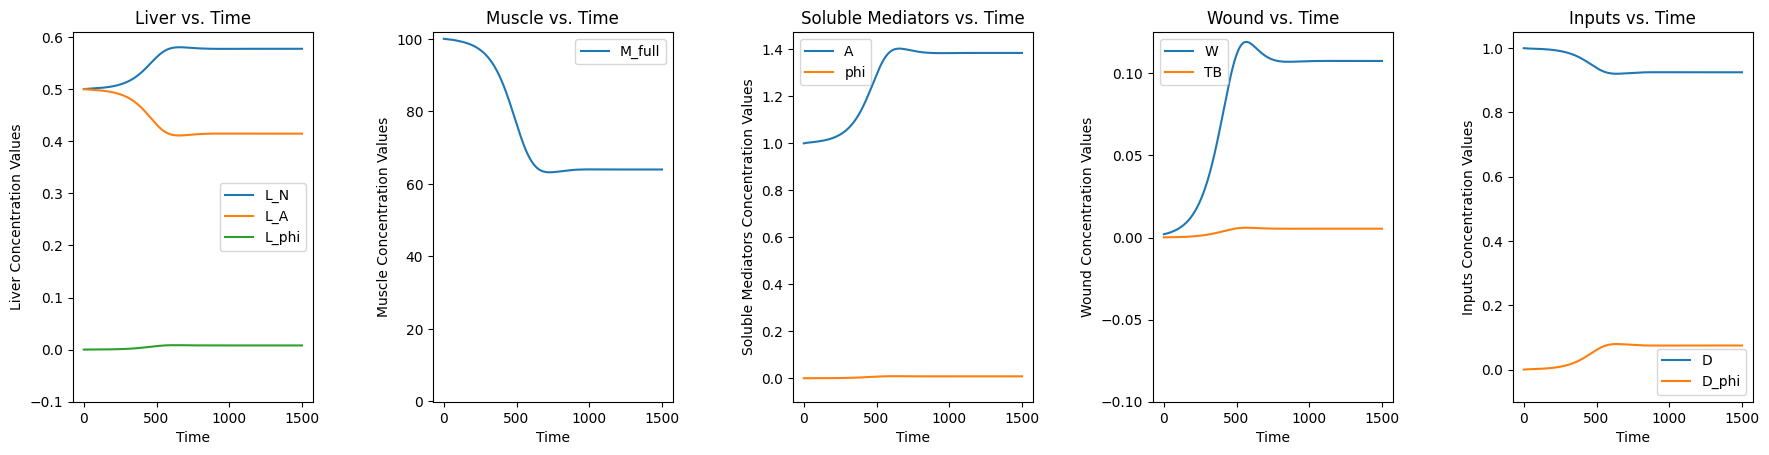

In [33]:
tbGrowthRate = 0.01
tbN = 20
initialTBPop = 0.0001

initWound = tbN * initialTBPop

diet = 1

woundValsVsTime = []

tuberculosisRxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI', 'TB'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['A', 'phi'], "Wound" : ['W', 'TB'], "Inputs" : ['D', 'D_phi']})

tuberculosisRxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0, initialTBPop])

tuberculosisRxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

#
tuberculosisRxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationGenerationParam, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

#
tuberculosisRxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

#
tuberculosisRxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


#
tuberculosisRxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

#
tuberculosisRxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



#This allows M_full to continue acting as an inflammation sink while not changing state
tuberculosisRxnFlask.addReaction("Reaction 7: M_full + phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})

#Note that the below reaction rate is 0: IMW is fully on
tuberculosisRxnFlask.addReaction("Reaction 22: M_full + phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


#This allows M_empty to continue acting as an inflammation sink while not changing state
tuberculosisRxnFlask.addReaction("Reaction 8: M_empty + phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})

#Note that the below reaction rate is 0: IMW is fully on
tuberculosisRxnFlask.addReaction("Reaction 23: M_empty + phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})



#The reactions governing replication
tuberculosisRxnFlask.addReaction("Reaction 27: TB -> TB + TB + nW", tbGrowthRate, reactantsDict = {'TB' : 1}, productsDict = {'TB' : 2, 'W' : tbN})

#The reaction where Mtb-infected cells also produce inflammation
tuberculosisRxnFlask.addReaction("Reaction 28: TB -> TB + phi", inflammationGenerationParam, reactantsDict = {'TB' : 1}, productsDict = {'TB' : 1, 'phi' : 1})

#The reactions governing Mtb-infected cells' destruction
tuberculosisRxnFlask.addReaction("Reaction 29: TB + pI -> naught", 1, reactantsDict = {'TB' : 1, 'pI' : 1}, productsDict = {})

print(tuberculosisRxnFlask.reactionDeriv(0, tuberculosisRxnFlask._initialCondition))

tuberculosisRxnFlask.runSystem(1500)

tuberculosisRxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

tbTimeVals = tuberculosisRxnFlask.latestSimulationOutput["t"]
tbValsVsTime = tuberculosisRxnFlask.latestSimulationOutput["y"][-1]


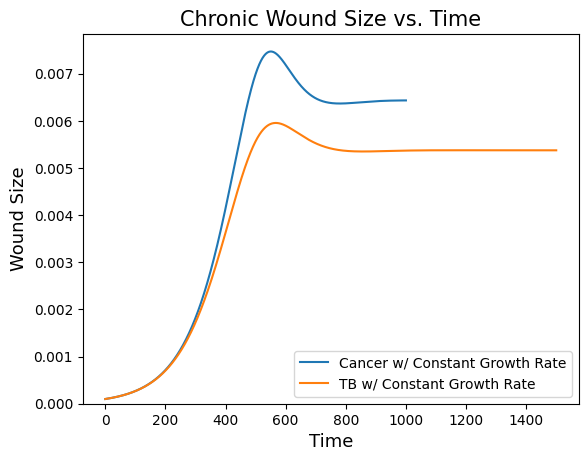

In [34]:
plt.plot(cancerTimeVals, cancerValsVsTime, label = "Cancer w/ Constant Growth Rate")
plt.plot(tbTimeVals, tbValsVsTime, label = "TB w/ Constant Growth Rate")

plt.title("Chronic Wound Size vs. Time", fontsize = 15)

plt.xlabel("Time", fontsize = 13)

plt.ylabel("Wound Size", fontsize = 13)

plt.ylim(bottom = 0)

plt.legend()

plt.savefig("FigureImages/Figure4Images/ChronicDiseaseTimecoursesVsTime.png")

The following code creates the bifurcation diagram showing how the steady state of weight changes in the system with increased growth rate

In [35]:
numPointsToTest = 20

In [36]:

cancerPopEndpoints = np.zeros(numPointsToTest)
cancerWeightEndpoints = np.zeros(numPointsToTest)

for k in range(numPointsToTest):

    cancerGrowthRate = 0.01 * (k / (numPointsToTest - 1))
    cancerN = 20
    initialCancerPop = 0.001

    initWound = cancerN * initialCancerPop

    diet = 1

    woundValsVsTime = []

    cancerRxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI', 'C'], components = {"Liver" : ['L_A', 'L_N','L_phi'], "Muscle" : ['M_full'], "Wound" : ['W', 'C'], "Soluble Mediators" : ['A', 'phi', 'pI'], "Diet" : ['D', 'D_phi']})

    cancerRxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0, initialCancerPop])

    cancerRxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

    #
    cancerRxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationGenerationParam, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

    #
    cancerRxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

    #
    cancerRxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


    #
    cancerRxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

    #
    cancerRxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



    #This allows M_full to continue acting as an inflammation sink while not changing state
    cancerRxnFlask.addReaction("Reaction 7: M_full + phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})

    #Note that the below reaction rate is 0: IMW is fully on
    cancerRxnFlask.addReaction("Reaction 22: M_full + phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    cancerRxnFlask.addReaction("Reaction 8: M_empty + phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})

    #Note that the below reaction rate is 0: IMW is fully on
    cancerRxnFlask.addReaction("Reaction 23: M_empty + phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})



    #The reactions governing replication
    cancerRxnFlask.addReaction("Reaction 24: C + A -> C + C + nW", cancerGrowthRate, reactantsDict = {'C' : 1, 'A' : 1}, productsDict = {'C' : 2, 'W' : cancerN})

    #The reaction where cancer cells also produce inflammation
    cancerRxnFlask.addReaction("Reaction 25: C -> C + phi", inflammationGenerationParam, reactantsDict = {'C' : 1}, productsDict = {'C' : 1, 'phi' : 1})

    #The reactions governing cancer destruction
    cancerRxnFlask.addReaction("Reaction 26: C + pI -> naught", 1, reactantsDict = {'C' : 1, 'pI' : 1}, productsDict = {})

    cancerRxnFlask.runSystem(2000)

    #cancerRxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    cancerEndpoint = cancerRxnFlask.getFinalValueOfSpecies('C')
    weightEndpoint = cancerRxnFlask.getFinalValueOfSpecies('M_full')

    cancerPopEndpoints[k] = cancerEndpoint
    cancerWeightEndpoints[k] = weightEndpoint




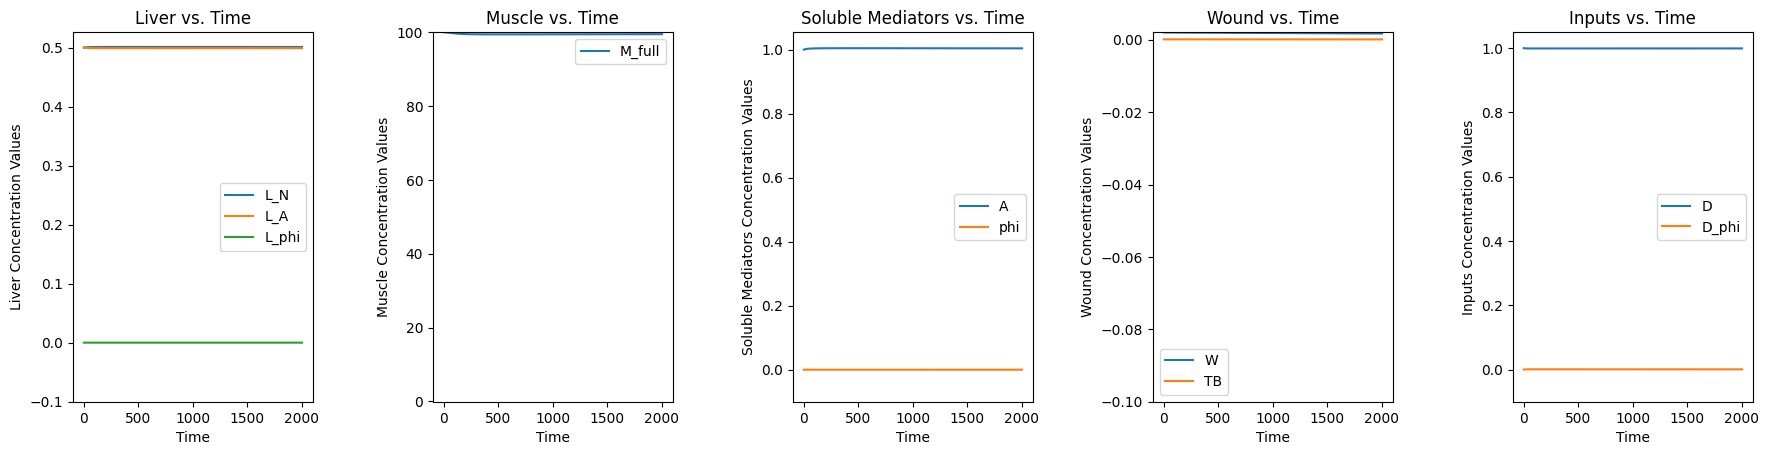

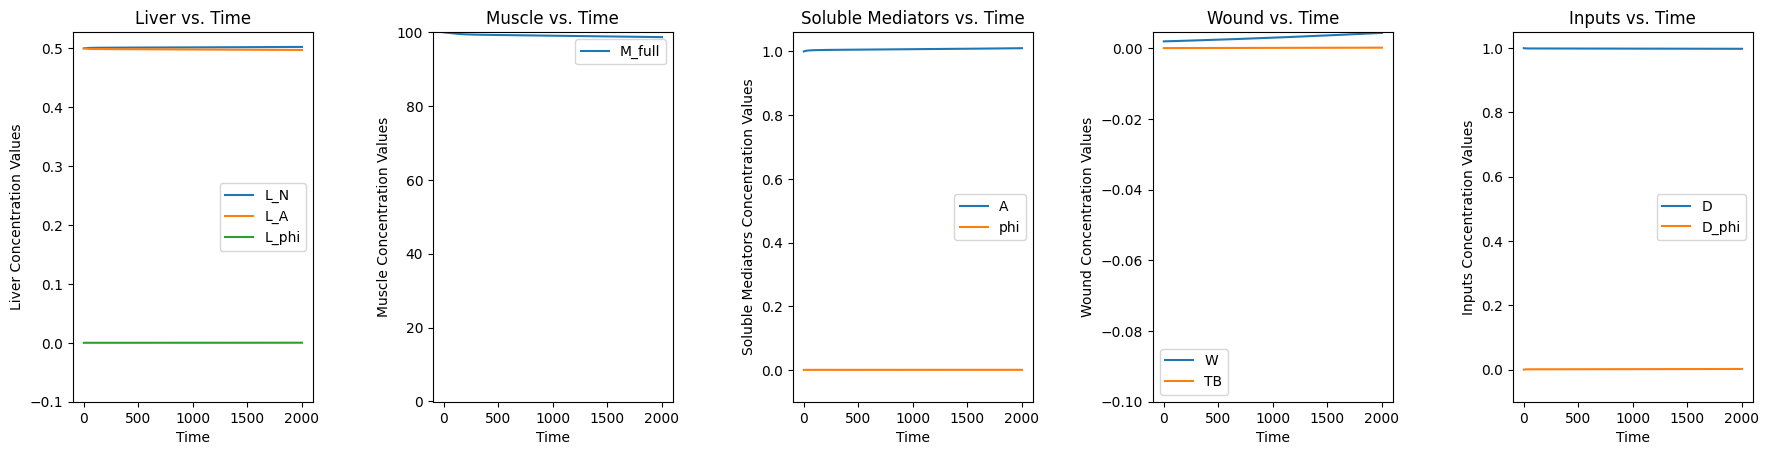

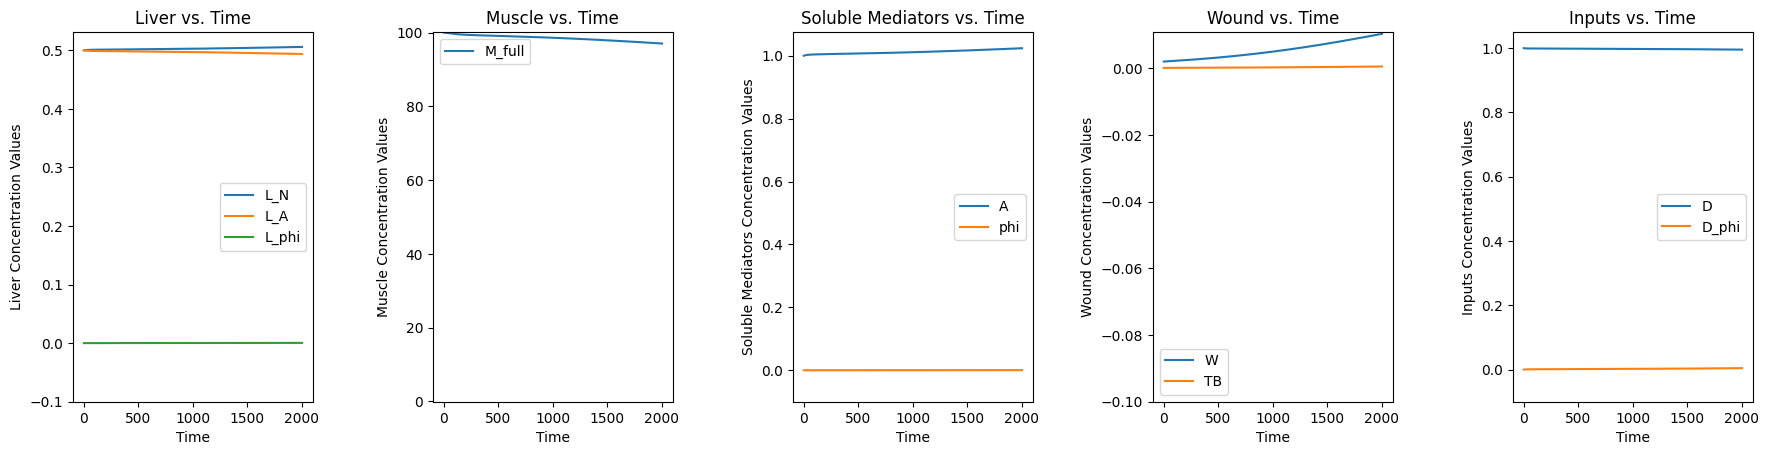

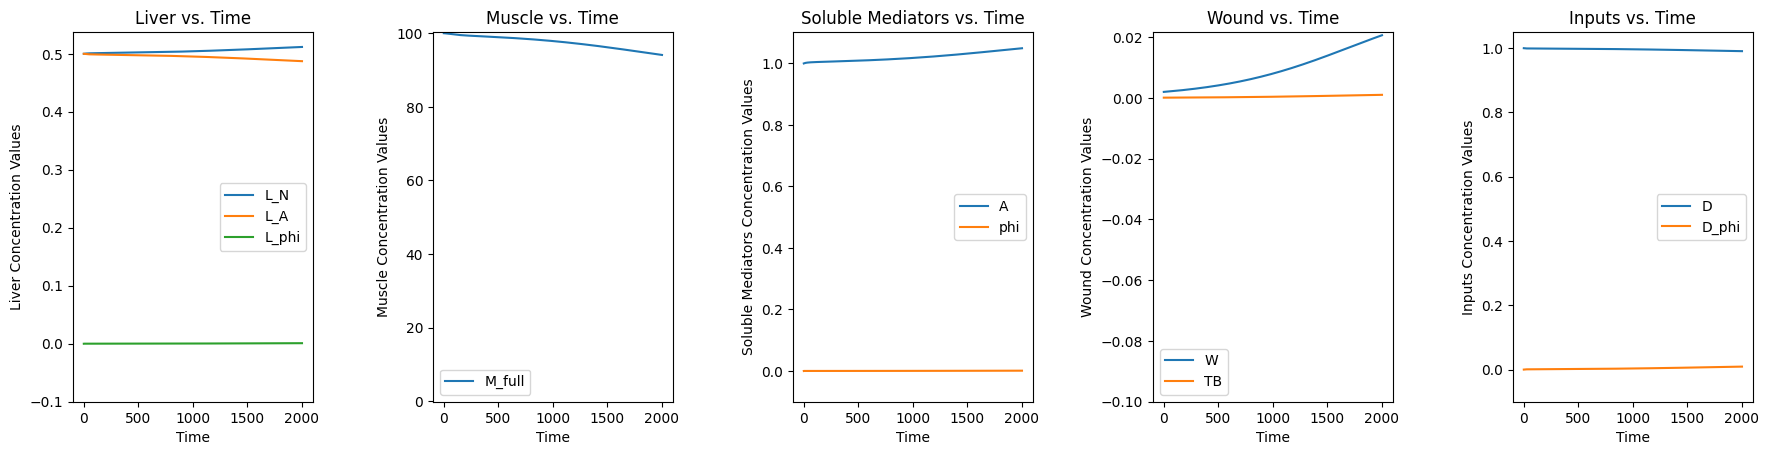

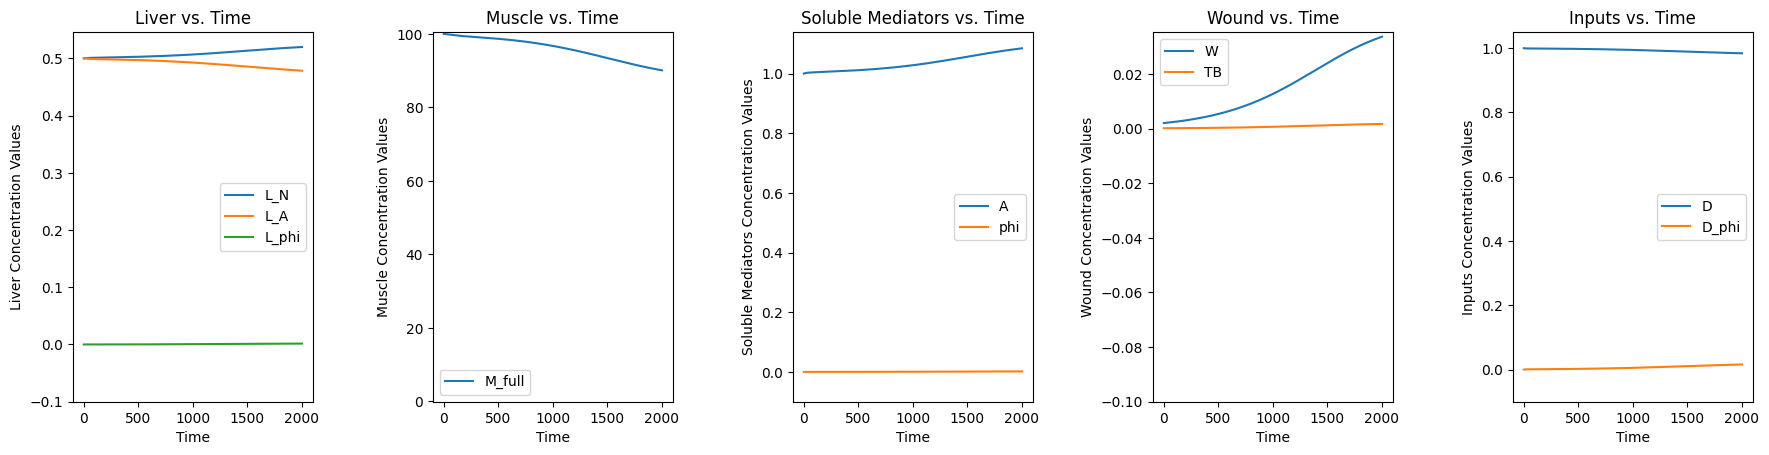

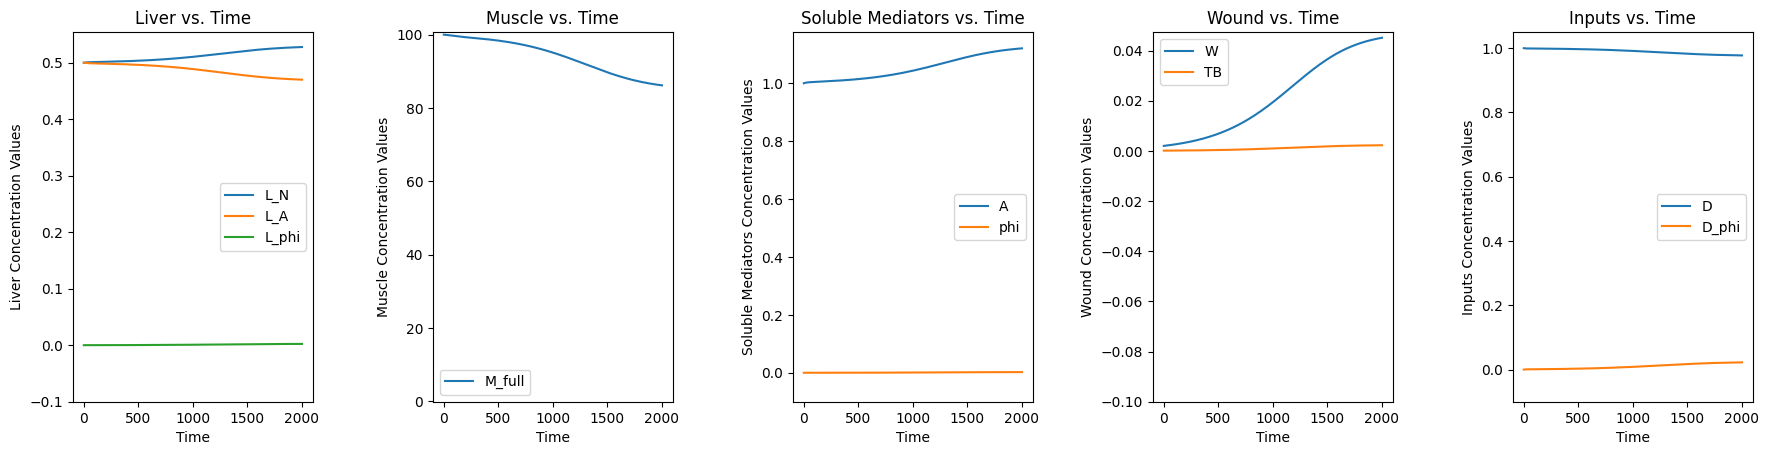

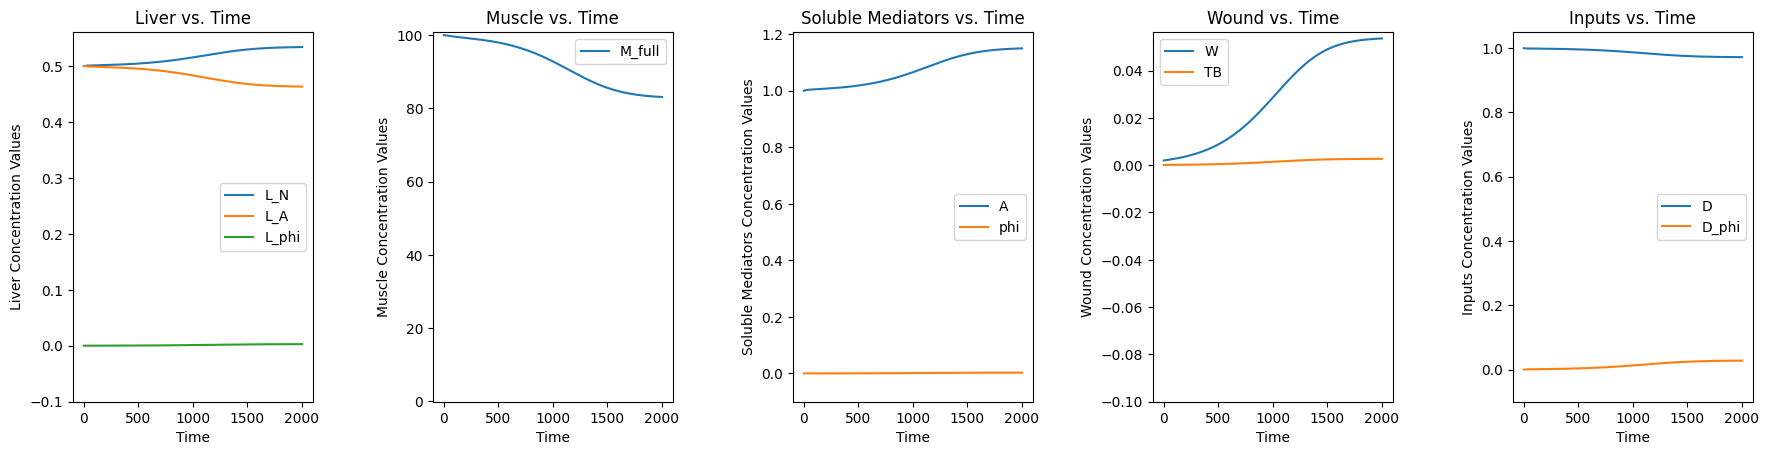

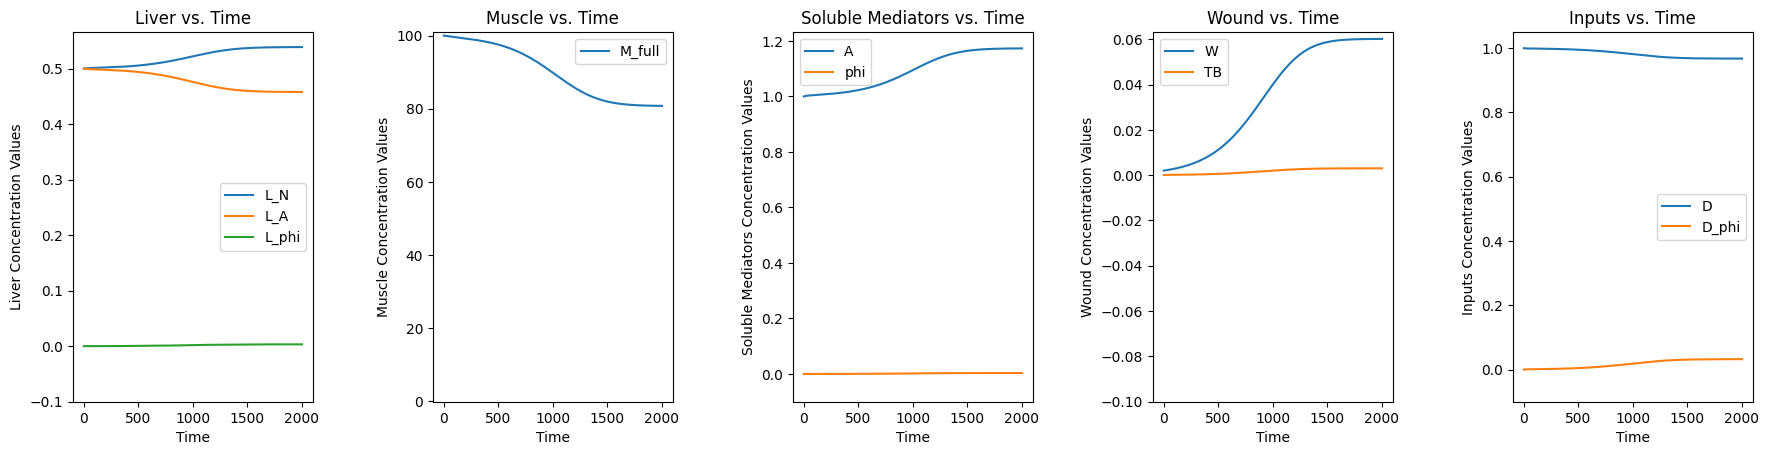

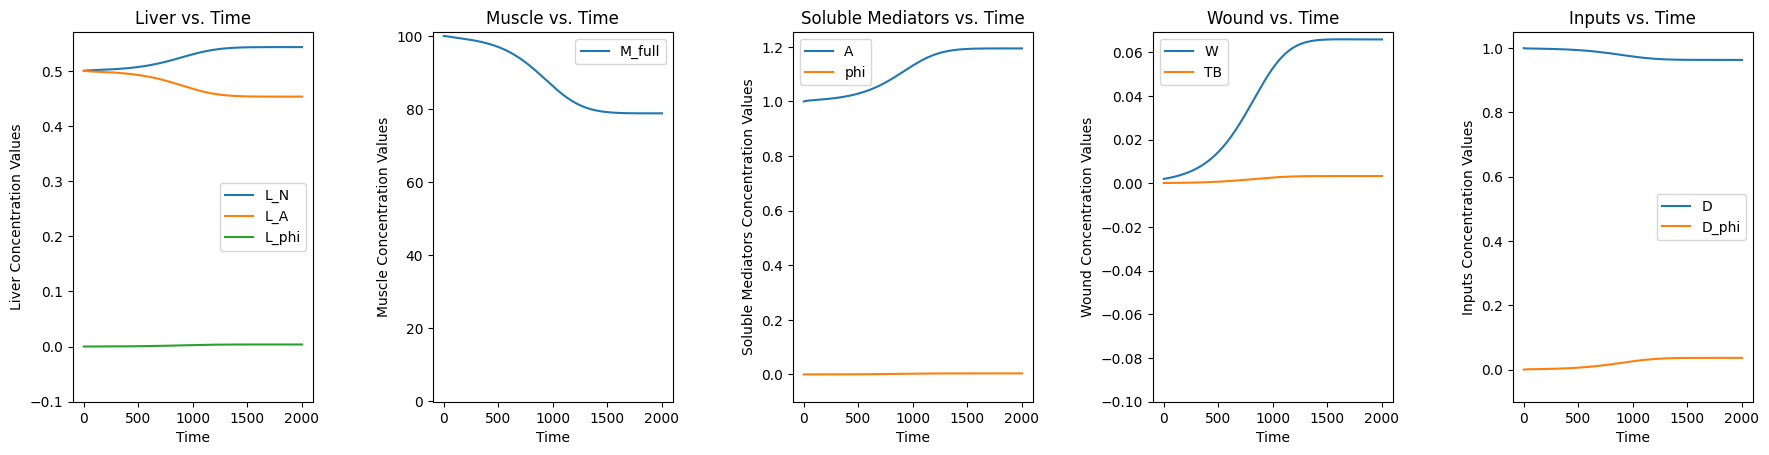

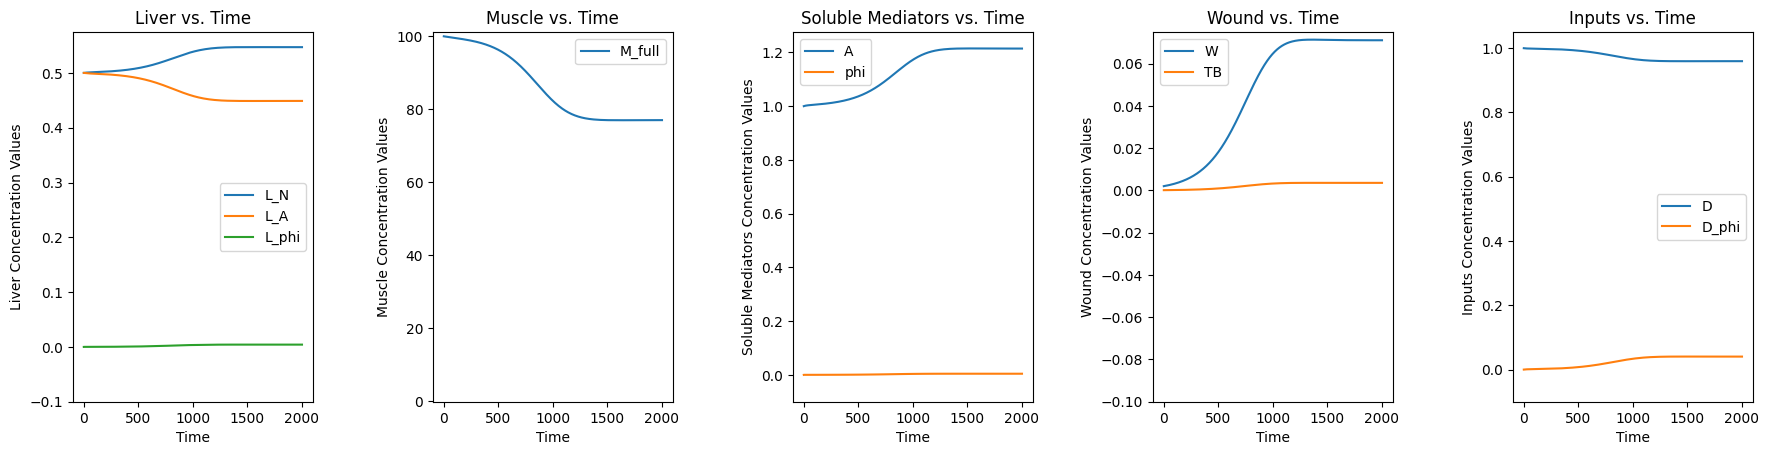

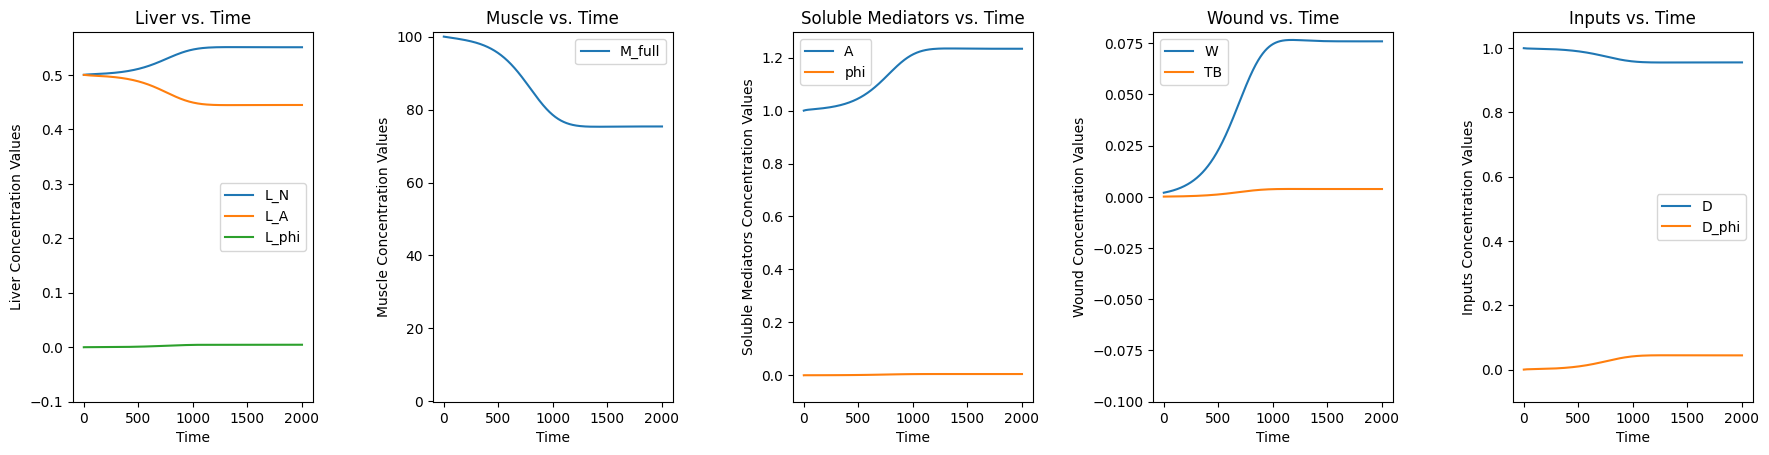

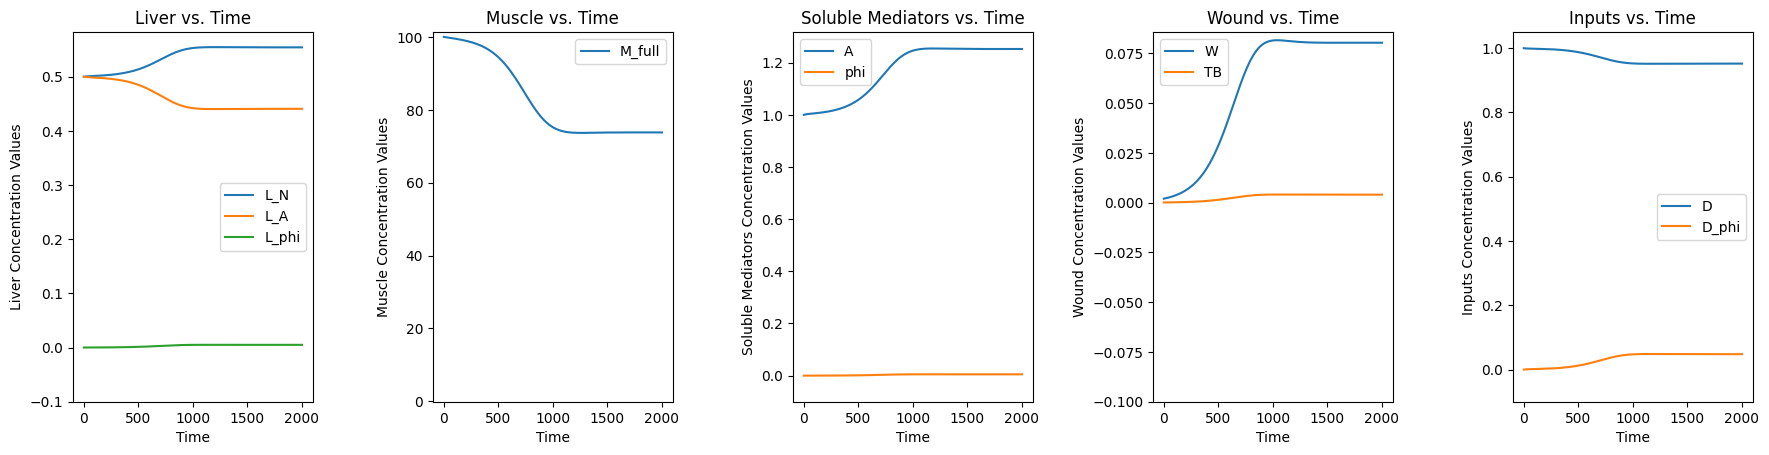

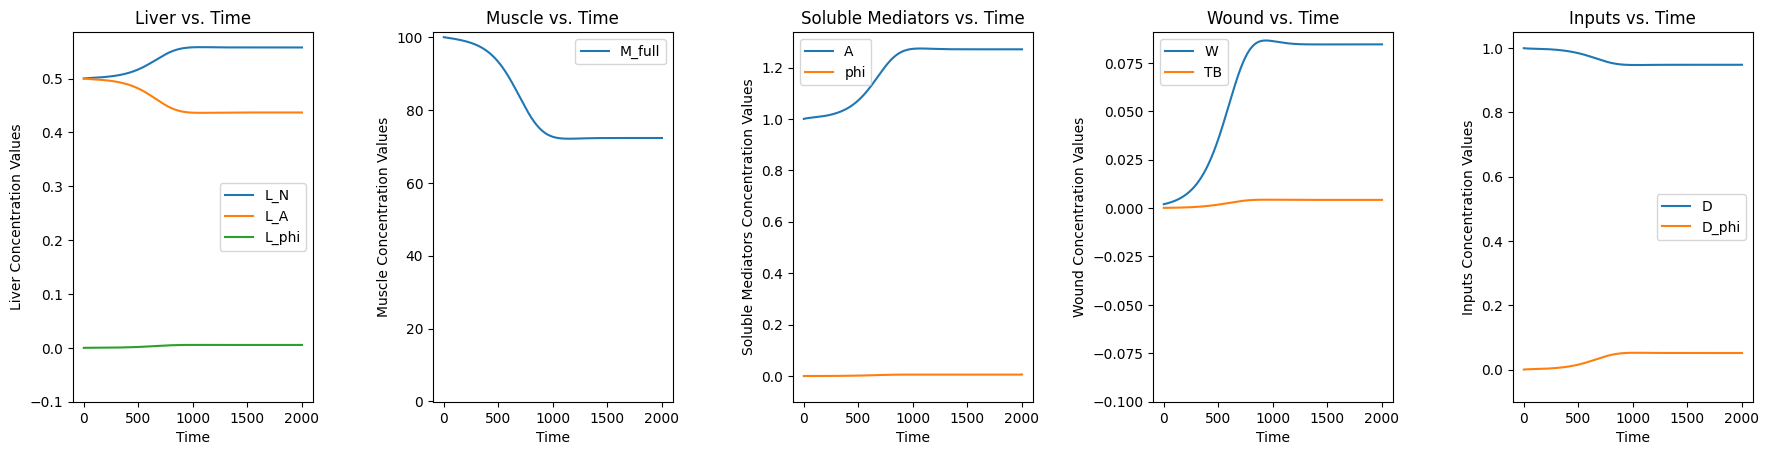

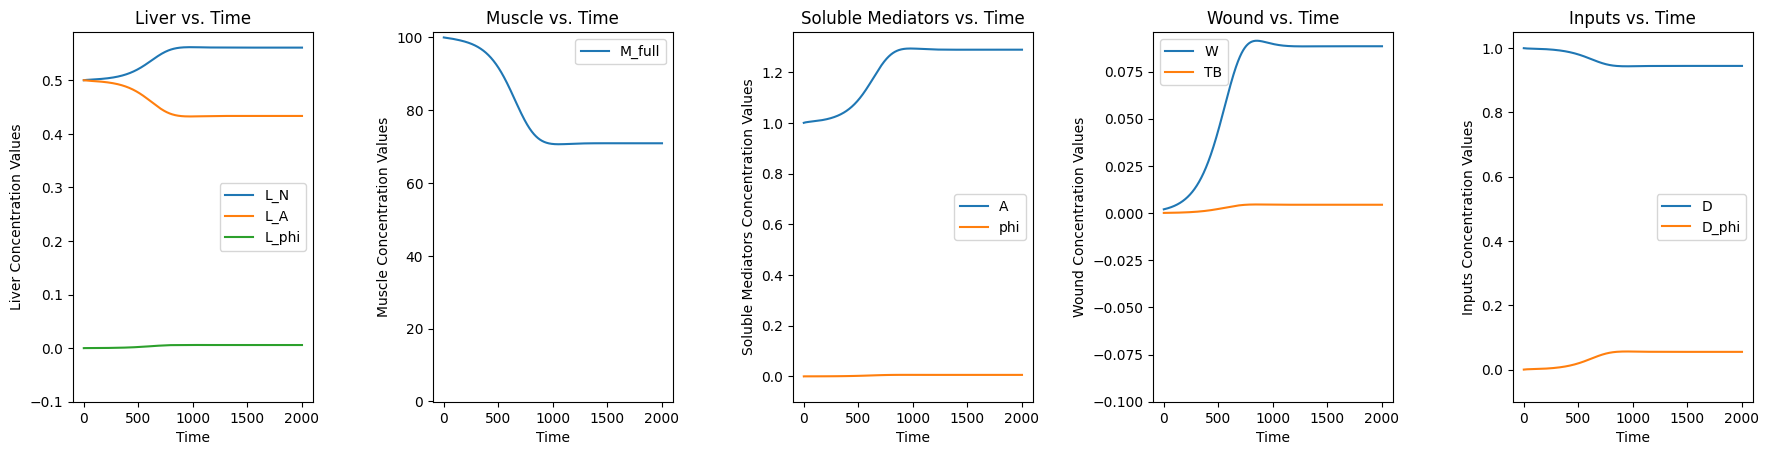

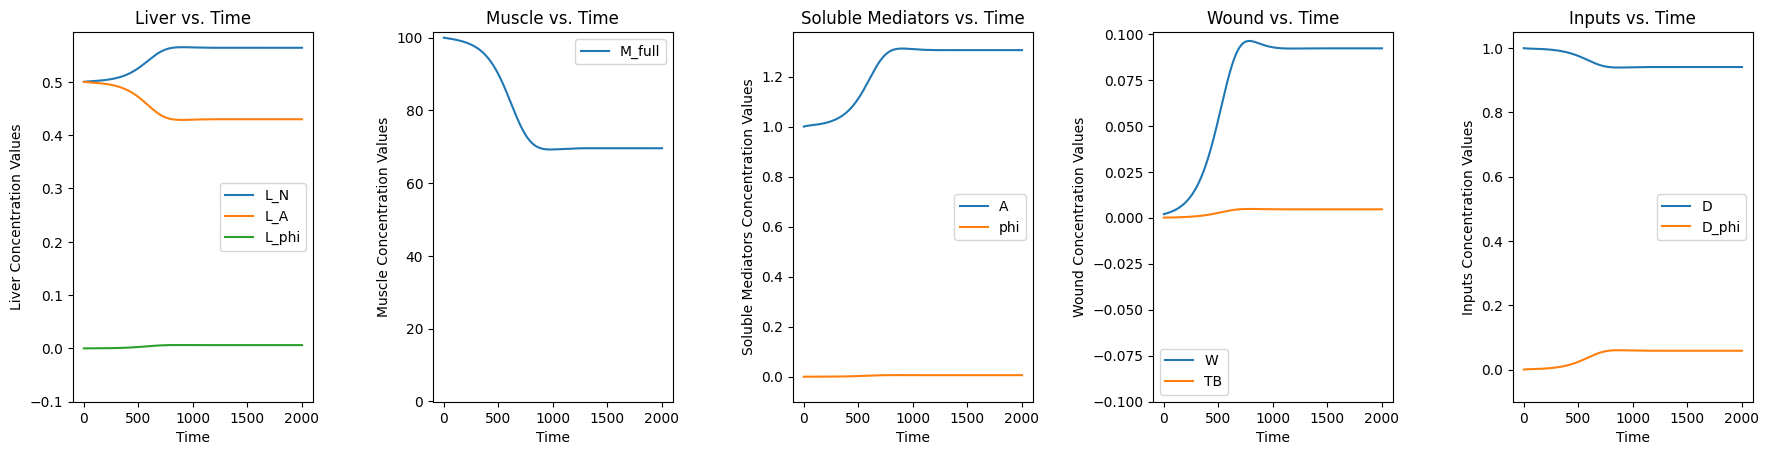

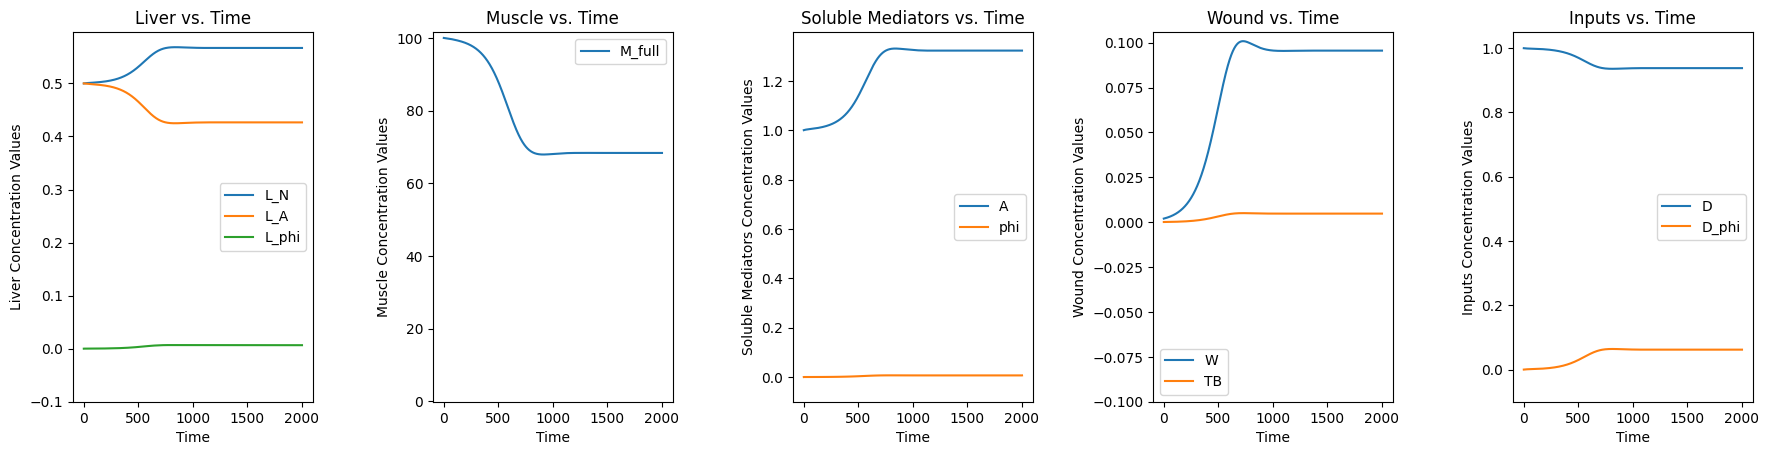

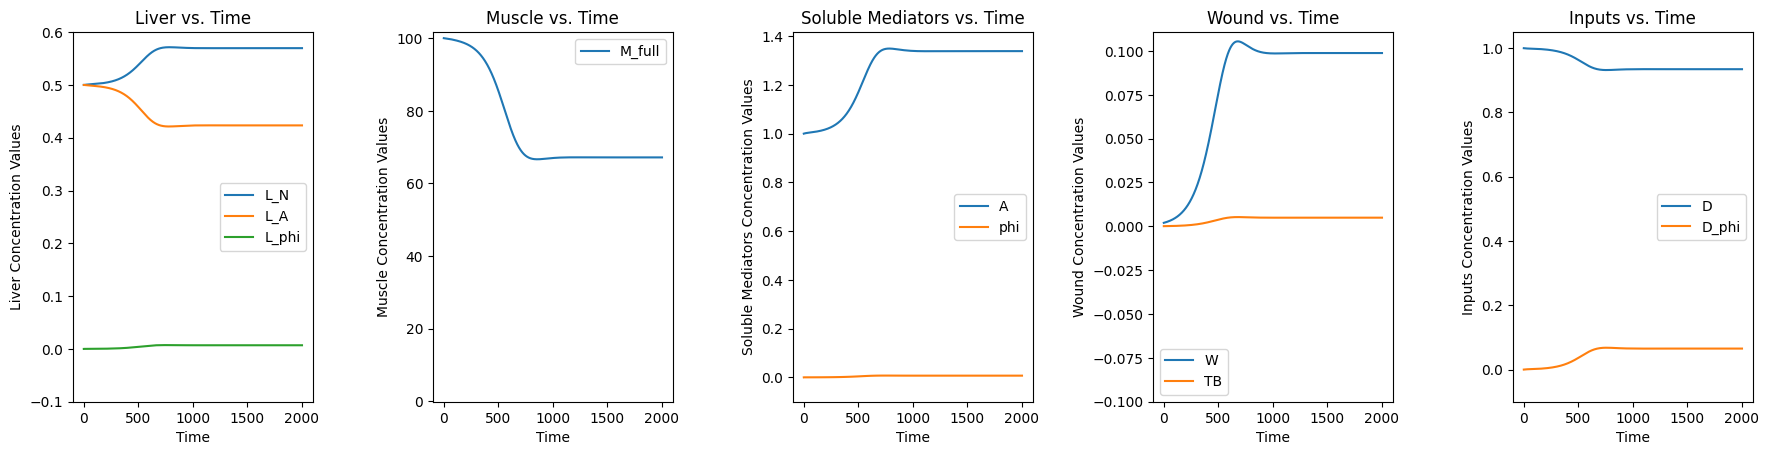

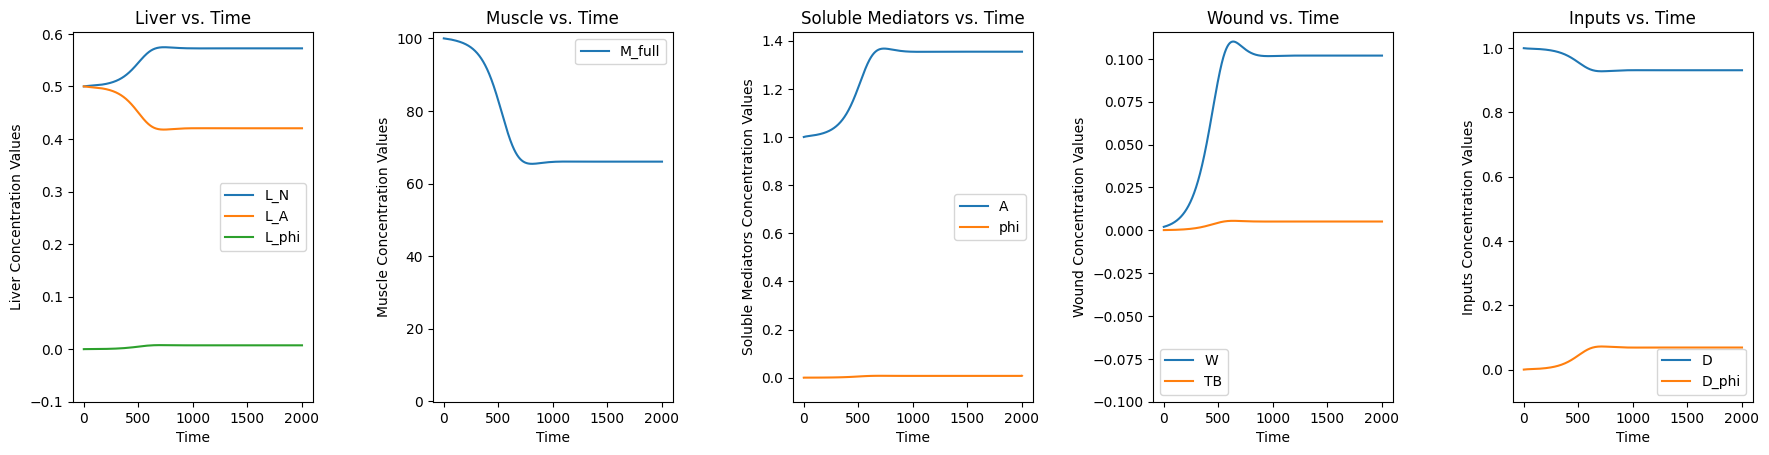

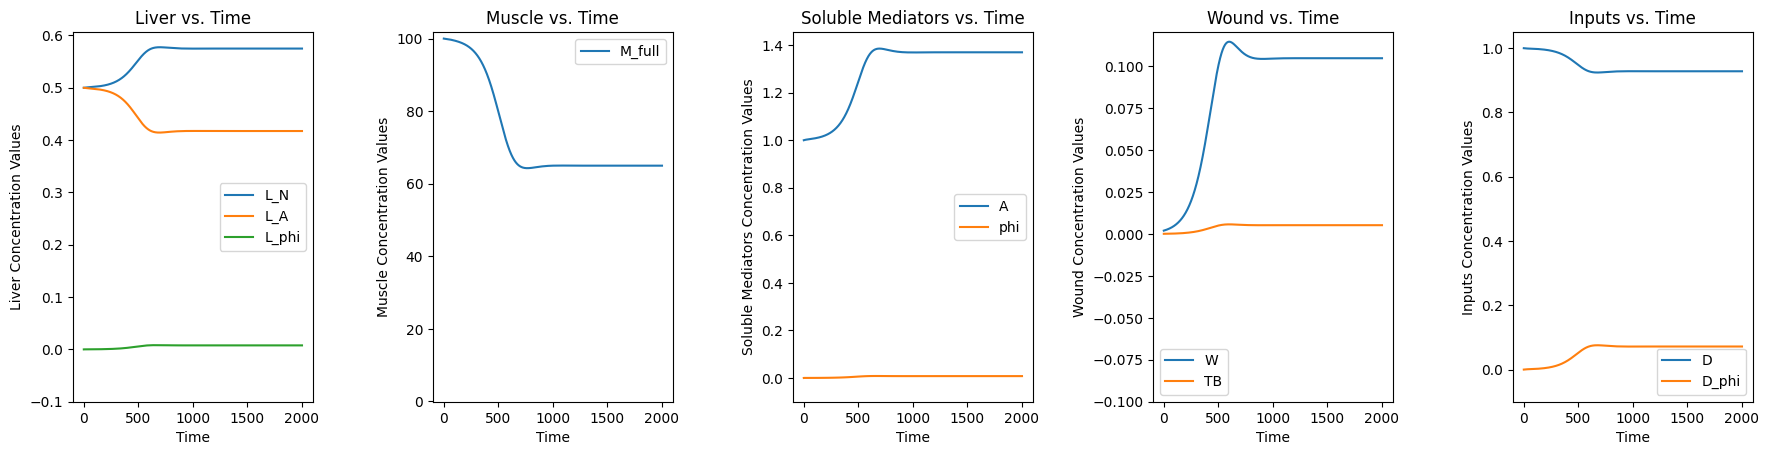

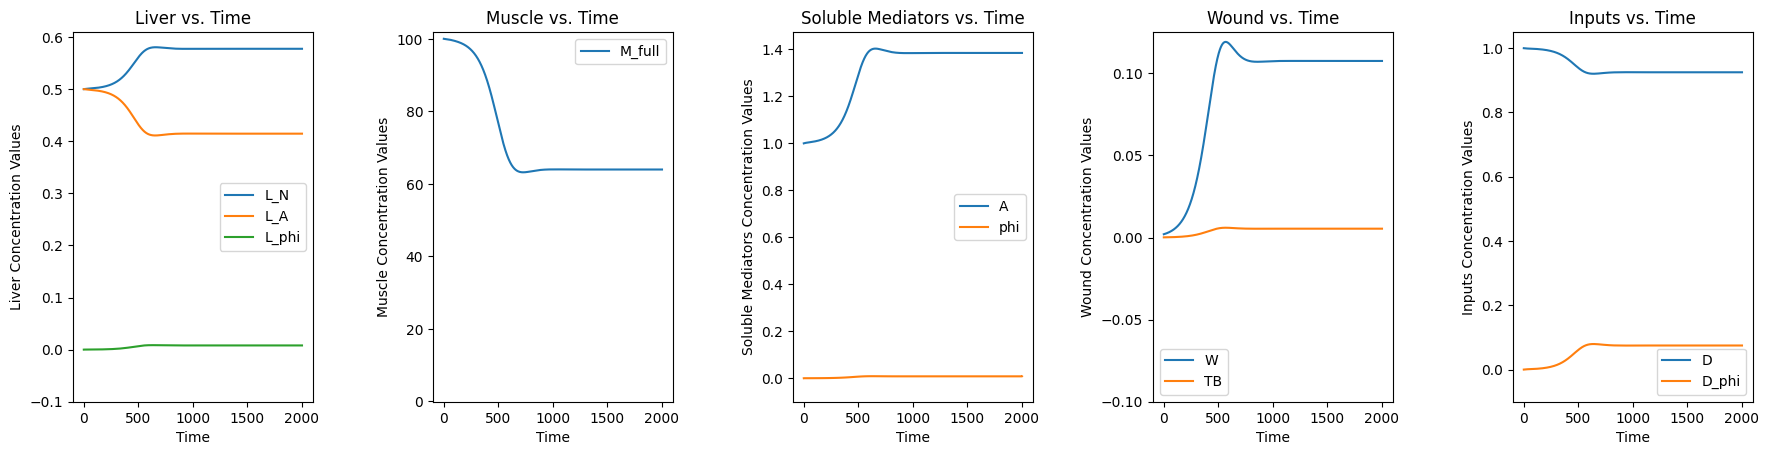

In [37]:
tbPopEndpoints = np.zeros(numPointsToTest)
tbWeightEndpoints = np.zeros(numPointsToTest)

for k in range(numPointsToTest):
    tbGrowthRate = 0.01 * (k / (numPointsToTest - 1))
    tbN = 20
    initialTBPop = 0.0001

    initWound = tbN * initialTBPop

    diet = 1

    woundValsVsTime = []

    tuberculosisRxnFlask = ReactionFlask(['W', 'D', 'D_phi', 'L_N', 'L_A', 'L_phi', 'M_full', 'M_empty', 'M_phi', 'M_ePhi', 'A', 'phi', 'pI', 'TB'], components = {"Liver" : ['L_N', 'L_E', 'L_A', 'L_phi'], "Muscle" : ['M_full'], "Soluble Mediators" : ['A', 'phi'], "Wound" : ['W', 'TB'], "Inputs" : ['D', 'D_phi']})

    tuberculosisRxnFlask.setInitialCondition([initWound, diet, 0, 0.5, 0.5, 0, 100, 100, 0, 0, 1, 0, 0, initialTBPop])

    tuberculosisRxnFlask.addReaction("Reaction 1: L_N -> L_A", 1, reactantsDict = {'L_N' : 1}, productsDict = {'L_A' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 2: L_A -> L_A + A", 1, reactantsDict = {'L_A' : 1}, productsDict = {'L_A' : 1, 'A' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 3: L_A + A -> L_N + A", 1, reactantsDict = {'L_A' : 1, 'A' : 1}, productsDict = {'L_N' : 1, 'A': 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 4: M_full -> M_empty + A", 1, reactantsDict = {'M_full' : 1}, productsDict = {'M_empty' : 1, 'A' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 5: M_empty + A -> M_full", 1, reactantsDict = {'M_empty' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 6: M_full + A -> M_full", 0.015, reactantsDict = {'M_full' : 1, 'A' : 1}, productsDict = {'M_full' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 9: M_phi -> M_ePhi + hA", 1, reactantsDict = {'M_phi' : 1}, productsDict = {'M_ePhi' : 1, 'A' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 10: M_phi -> M_full", 0.01, reactantsDict = {'M_phi' : 1}, productsDict = {'M_full' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 11: M_ePhi -> M_empty", 0.01, reactantsDict = {'M_ePhi' : 1}, productsDict = {'M_empty' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 12: W -> W + phi", inflammationGenerationParam, reactantsDict = {'W' : 1}, productsDict = {'W' : 1, 'phi' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 13: L_N + phi -> L_phi", 1, reactantsDict = {'L_N' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 14: L_A + phi -> L_phi", 1, reactantsDict = {'L_A' : 1, 'phi' : 1}, productsDict = {'L_phi' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 15: L_phi -> L_N", 1, reactantsDict = {'L_phi' : 1}, productsDict = {'L_N' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 16: L_phi + A -> L_phi + pI", 1, reactantsDict = {'L_phi' : 1, 'A' : 1}, productsDict = {'L_phi' : 1, 'pI' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 17: W + pI -> naught", 1, reactantsDict = {'W' : 1, 'pI' : 1}, productsDict = {})

    #
    tuberculosisRxnFlask.addReaction("Reaction 18: pI -> naught", 1, reactantsDict = {'pI' : 1}, productsDict = {})

    #
    tuberculosisRxnFlask.addReaction("Reaction 19: D -> D + A", 1, reactantsDict = {'D' : 1}, productsDict = {'D' : 1, 'A' : 1})


    #
    tuberculosisRxnFlask.addReaction("Reaction 20: D + phi -> D_phi + phi", 1, reactantsDict = {'D' : 1, 'phi' : 1}, productsDict = {'D_phi' : 1, 'phi' : 1})

    #
    tuberculosisRxnFlask.addReaction("Reaction 21: D_phi -> D", 0.1, reactantsDict = {'D_phi': 1}, productsDict = {'D' : 1})



    #This allows M_full to continue acting as an inflammation sink while not changing state
    tuberculosisRxnFlask.addReaction("Reaction 7: M_full + phi -> M_phi" , 1, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_phi' : 1})

    #Note that the below reaction rate is 0: IMW is fully on
    tuberculosisRxnFlask.addReaction("Reaction 22: M_full + phi -> M_full" , 0, reactantsDict = {'M_full' : 1, 'phi' : 1}, productsDict = {'M_full' : 1})


    #This allows M_empty to continue acting as an inflammation sink while not changing state
    tuberculosisRxnFlask.addReaction("Reaction 8: M_empty + phi -> M_ePhi" , 1, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_ePhi' : 1})

    #Note that the below reaction rate is 0: IMW is fully on
    tuberculosisRxnFlask.addReaction("Reaction 23: M_empty + phi -> M_empty", 0, reactantsDict = {'M_empty' : 1, 'phi' : 1}, productsDict = {'M_empty' : 1})



    #The reactions governing replication
    tuberculosisRxnFlask.addReaction("Reaction 27: TB -> TB + TB + nW", tbGrowthRate, reactantsDict = {'TB' : 1}, productsDict = {'TB' : 2, 'W' : tbN})

    #The reaction where Mtb-infected cells also produce inflammation
    tuberculosisRxnFlask.addReaction("Reaction 28: TB -> TB + phi", inflammationGenerationParam, reactantsDict = {'TB' : 1}, productsDict = {'TB' : 1, 'phi' : 1})

    #The reactions governing Mtb-infected cells' destruction
    tuberculosisRxnFlask.addReaction("Reaction 29: TB + pI -> naught", 1, reactantsDict = {'TB' : 1, 'pI' : 1}, productsDict = {})

    #print(tuberculosisRxnFlask.reactionDeriv(0, cancerRxnFlask._initialCondition))

    tuberculosisRxnFlask.runSystem(2000)

    tuberculosisRxnFlask.plotSystem(widthSpacing = 0.5, rightEdgeOfPlots = 2.75)

    tbEndpoint = tuberculosisRxnFlask.getFinalValueOfSpecies('TB')
    weightEndpoint = tuberculosisRxnFlask.getFinalValueOfSpecies('M_full')

    tbPopEndpoints[k] = tbEndpoint
    tbWeightEndpoints[k] = weightEndpoint


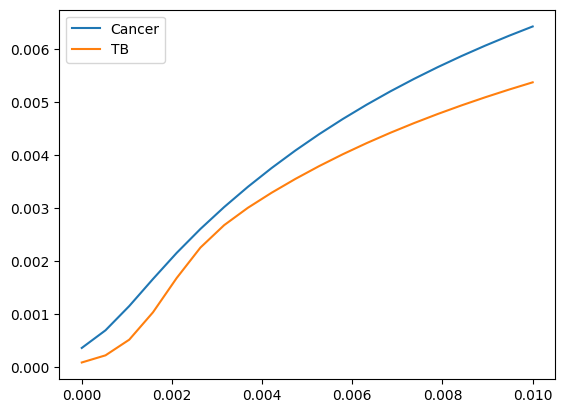

In [38]:
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerPopEndpoints, label =  "Cancer")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], tbPopEndpoints, label = "TB")
plt.legend()

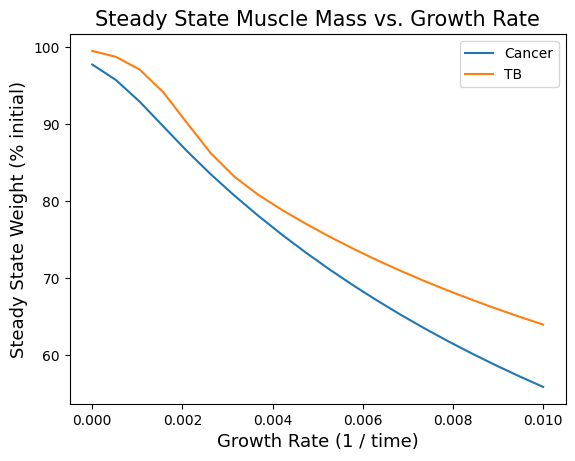

In [ ]:
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints, label =  "Cancer")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], tbWeightEndpoints, label = "TB")

plt.title("Steady State Muscle Mass vs. Growth Rate", fontsize = 15)
plt.xlabel("Growth Rate (1 / time)", fontsize = 13)
plt.ylabel("Steady State Weight (% initial)", fontsize = 13)
plt.legend()

plt.savefig("FigureImages/Figure4Images/SteadyStateWeightvsGrowthRate.png")

-4259.497167093875


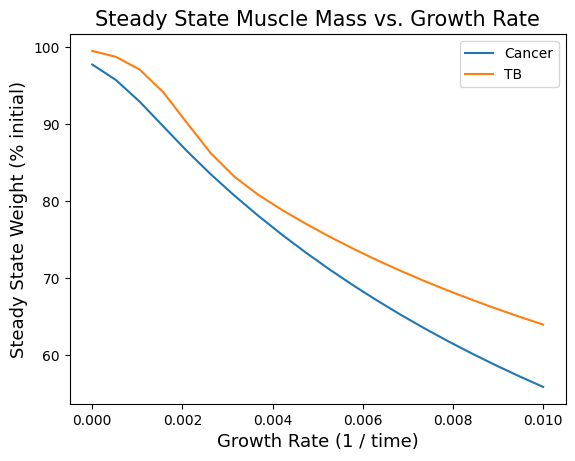

In [42]:
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints, label =  "Cancer")
plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], tbWeightEndpoints, label = "TB")

linearCancerWeightSlope, linearCancerWeightIntercept = np.polyfit([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], cancerWeightEndpoints, 1)

print(linearCancerWeightSlope)
#plt.plot([0.01 * (k / (numPointsToTest - 1)) for k in range(numPointsToTest)], linearCancerWeight)

plt.title("Steady State Muscle Mass vs. Growth Rate", fontsize = 15)
plt.xlabel("Growth Rate (1 / time)", fontsize = 13)
plt.ylabel("Steady State Weight (% initial)", fontsize = 13)
plt.legend()